# Zela · IA & Machine Learning
## Quais sinais da triagem indicam risco de morte num caso respiratório grave?

**CitizenTech:** Zela, triagem e orientação em saúde para a comunidade da Vila Andrade (São Paulo).
A Zela classifica cada relato em **verde** (cuidar em casa), **amarelo** (UBS com prioridade) ou
**vermelho** (emergência). A regra de ouro do projeto é: *um sinal de alerta nunca pode ser rebaixado*.

**Pergunta de ML:** entre as pessoas que moram em São Paulo e foram notificadas com Síndrome Respiratória
Aguda Grave (SRAG), é possível prever, **só com o que se sabe na chegada** (sintomas, idade, gestação,
doenças pré-existentes e vacinação), quem **evolui para óbito**? E quais sinais pesam mais?

**Por que isso importa para o cidadão:** o vermelho da Zela existe para que ninguém em risco de morrer fique
esperando na fila. Se os dados reais mostram quais sinais e perfis antecedem o óbito, a Zela sabe quais relatos
precisam ir direto para a emergência (SAMU 192) e quais podem ser acompanhados na UBS ou em casa.

**Dados (reais e públicos):** SIVEP-Gripe, Banco de SRAG 2019 a 2026, Ministério da Saúde / OpenDataSUS
(<https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026>), anos epidemiológicos **2024** (base congelada,
versão de 23/03/2026) e **2025** (base viva, versão de 16/11/2026), filtrados para residentes do município de
São Paulo (IBGE 355030). Os dados são anonimizados pelo Ministério da Saúde (LGPD). Detalhes em `dados/README.md`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
SEMENTE = 42
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="Blues_d")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

## 1. Problema e dados reais

O recorte foi gerado por `preparar_dados.py` a partir dos CSVs nacionais (cerca de 700 MB) e guardado em
`dados/srag_sao_paulo_2024_2025.csv.gz`. Cada linha é **uma notificação de SRAG** de alguém que mora em São Paulo.

In [2]:
bruto = pd.read_csv("dados/srag_sao_paulo_2024_2025.csv.gz", dtype=str)
bruto["DT_SIN_PRI"] = pd.to_datetime(bruto["DT_SIN_PRI"].str[:10], errors="coerce")
print(f"Notificações: {len(bruto):,}  |  colunas: {bruto.shape[1]}")
print("Início dos sintomas de", bruto["DT_SIN_PRI"].min().date(), "a", bruto["DT_SIN_PRI"].max().date())
bruto.groupby("ANO_BASE").size().rename("notificações").to_frame()

Notificações: 35,080  |  colunas: 47
Início dos sintomas de 2023-12-31 a 2026-01-03


,notificações
ANO_BASE,
2024,17408
2025,17672


### Variável alvo: evoluiu para óbito?

No dicionário do SIVEP-Gripe, `EVOLUCAO` vale **1 = cura**, **2 = óbito por SRAG**, **3 = óbito por outras
causas** e **9 = ignorado**. Ficamos só com cura (0) e óbito por SRAG (1). Óbito por outra causa, ignorado e casos
ainda em aberto saem da análise, porque não dizem nada sobre a gravidade da doença respiratória.

> Antes desta pergunta testamos prever **ida para a UTI**. O modelo ficou fraco (ROC-AUC 0,58 em 2025): entre
> pessoas já internadas com SRAG, os sintomas quase não separam quem vai para a UTI, e essa decisão depende muito
> de vaga e de cada hospital. O óbito é um desfecho mais objetivo e mais ligado ao que a Zela quer evitar.

In [3]:
dados = bruto[bruto["EVOLUCAO"].isin(["1", "2"])].copy()
dados["obito"] = (dados["EVOLUCAO"] == "2").astype(int)
print(f"Casos com desfecho conhecido: {len(dados):,} de {len(bruto):,} ({len(dados)/len(bruto):.1%})")
(dados.groupby("ANO_BASE")["obito"]
      .agg(casos="size", obitos="sum", taxa_obito="mean")
      .style.format({"taxa_obito": "{:.1%}"}))

Casos com desfecho conhecido: 33,875 de 35,080 (96.6%)


,casos,obitos,taxa_obito
ANO_BASE,,,
2024,16662,1204,7.2%
2025,17213,1446,8.4%


## 2. Preparação dos dados

**Codificação.** As perguntas do SIVEP-Gripe usam 1 = sim, 2 = não, 9 = ignorado. Transformamos em 1 / 0 e deixamos
"ignorado" ou vazio como valor faltante (`NaN`): o XGBoost aprende sozinho para que lado mandar o faltante, sem que a
gente invente um valor.

**O que entra (o que a Zela consegue perguntar na triagem):**
- perfil: idade em anos, sexo, gestante, puérpera;
- sinais e sintomas: febre, tosse, dor de garganta, falta de ar (dispneia), desconforto respiratório, saturação de
  O₂ < 95%, diarreia, vômito, dor abdominal, cansaço, perda de olfato, perda de paladar;
- doenças pré-existentes: coração, sangue, síndrome de Down, fígado, asma, diabetes, neurológica, pulmão,
  imunidade baixa, rins, obesidade;
- vacina contra gripe e contra covid.

**O que fica de fora, e por quê:**
- **Vazamento de informação**: ida para a UTI, suporte ventilatório, classificação final do vírus e datas de
  internação só existem *depois* da chegada ao hospital. Usá-los faria o modelo "colar" a resposta.
- **Tabagismo**: o campo `TABAG` vem 100% vazio nas bases de 2024 e 2025. Do jeito que as comorbidades são
  codificadas (abaixo), ele viraria um disfarce de "tem fator de risco marcado", então ficou de fora.
- **Ética**: raça/cor e escolaridade não entram. A Zela não pergunta isso na triagem, e não queremos um modelo que
  priorize ou rebaixe alguém por esses atributos.
- Comorbidades: no SIVEP-Gripe elas só são preenchidas quando o campo "fator de risco" é marcado. Quando não há fator de
  risco, consideramos que a pessoa **não** tem a doença (0), em vez de faltante.

In [4]:
SINTOMAS = {"FEBRE": "febre", "TOSSE": "tosse", "GARGANTA": "dor_garganta", "DISPNEIA": "falta_de_ar",
            "DESC_RESP": "desconforto_respiratorio", "SATURACAO": "saturacao_baixa", "DIARREIA": "diarreia",
            "VOMITO": "vomito", "DOR_ABD": "dor_abdominal", "FADIGA": "cansaco", "PERD_OLFT": "perda_olfato",
            "PERD_PALA": "perda_paladar"}
COMORBIDADES = {"CARDIOPATI": "doenca_coracao", "HEMATOLOGI": "doenca_sangue", "SIND_DOWN": "sindrome_down",
                "HEPATICA": "doenca_figado", "ASMA": "asma", "DIABETES": "diabetes",
                "NEUROLOGIC": "doenca_neurologica", "PNEUMOPATI": "doenca_pulmao",
                "IMUNODEPRE": "imunidade_baixa", "RENAL": "doenca_rins", "OBESIDADE": "obesidade",
                "PUERPERA": "puerpera"}


def sim_nao(serie: pd.Series) -> pd.Series:
    """1 -> 1 (sim), 2 -> 0 (não), 9/vazio -> NaN (ignorado)."""
    return serie.map({"1": 1.0, "2": 0.0})


def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = pd.DataFrame(index=df.index)
    idade = pd.to_numeric(df["NU_IDADE_N"], errors="coerce")
    divisor = df["TP_IDADE"].map({"1": 365.25, "2": 12.0, "3": 1.0})   # 1 = dias, 2 = meses, 3 = anos
    x["idade_anos"] = (idade / divisor).clip(0, 110)
    x["sexo_masculino"] = df["CS_SEXO"].map({"M": 1.0, "F": 0.0})
    x["gestante"] = df["CS_GESTANT"].map(
        {"1": 1.0, "2": 1.0, "3": 1.0, "4": 1.0, "5": 0.0, "6": 0.0, "0": 0.0})
    for coluna, nome in SINTOMAS.items():
        x[nome] = sim_nao(df[coluna])
    tem_fator = df["FATOR_RISC"].eq("1")
    for coluna, nome in COMORBIDADES.items():
        valor = sim_nao(df[coluna])
        x[nome] = valor.where(tem_fator, 0.0)        # sem fator de risco marcado = não tem
    x["vacina_gripe"] = sim_nao(df["VACINA"])
    x["vacina_covid"] = sim_nao(df["VACINA_COV"])
    # resumos simples, fáceis de explicar
    x["qtd_sintomas"] = x[list(SINTOMAS.values())].sum(axis=1, min_count=1)
    x["qtd_comorbidades"] = x[list(COMORBIDADES.values())].sum(axis=1, min_count=1)
    return x


X_todos = preparar(dados)
y_todos = dados["obito"]
print(f"{X_todos.shape[1]} variáveis de entrada")
(X_todos.isna().mean().sort_values(ascending=False).head(8)
 .rename("faltantes").to_frame().style.format("{:.1%}"))

31 variáveis de entrada


,faltantes
perda_paladar,38.8%
perda_olfato,38.7%
dor_abdominal,37.2%
dor_garganta,35.3%
diarreia,34.5%
vomito,33.7%
cansaco,33.2%
vacina_gripe,25.1%


### Um primeiro olhar: quem tem cada sinal morre mais?

Comparamos a taxa de óbito de quem **tem** o sinal com a de quem **não tem**. É só uma leitura descritiva (não
considera os outros sinais ao mesmo tempo, isso é o que o modelo faz), mas já mostra o tamanho do efeito.

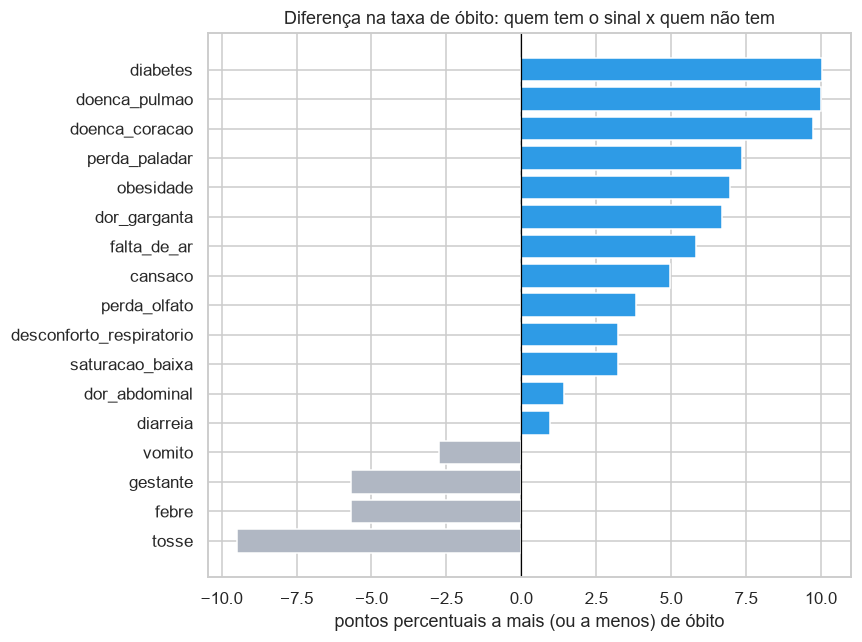

,sinal,óbito com o sinal,óbito sem o sinal,pessoas com o sinal,diferenca
14,diabetes,16.3%,6.2%,2966,+10.0%
15,doenca_pulmao,16.5%,6.5%,1538,+10.0%
13,doenca_coracao,15.6%,5.9%,4948,+9.7%
11,perda_paladar,14.5%,7.2%,392,+7.4%
16,obesidade,13.6%,6.6%,508,+6.9%
2,dor_garganta,14.1%,7.4%,3132,+6.7%
3,falta_de_ar,10.0%,4.2%,20653,+5.8%
9,cansaco,11.4%,6.4%,5138,+4.9%
10,perda_olfato,11.1%,7.3%,288,+3.8%
4,desconforto_respiratorio,9.1%,5.9%,21709,+3.2%


In [5]:
linhas = []
for nome in list(SINTOMAS.values()) + ["gestante", "doenca_coracao", "diabetes", "doenca_pulmao", "obesidade"]:
    com = y_todos[X_todos[nome] == 1]
    sem = y_todos[X_todos[nome] == 0]
    if len(com) >= 50 and len(sem) >= 50:
        linhas.append({"sinal": nome, "óbito com o sinal": com.mean(), "óbito sem o sinal": sem.mean(),
                       "pessoas com o sinal": len(com)})
efeito = (pd.DataFrame(linhas)
          .assign(diferenca=lambda d: d["óbito com o sinal"] - d["óbito sem o sinal"])
          .sort_values("diferenca", ascending=False))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(efeito["sinal"], efeito["diferenca"] * 100,
        color=np.where(efeito["diferenca"] > 0, "#2E9BE6", "#B0B7C3"))
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("pontos percentuais a mais (ou a menos) de óbito")
ax.set_title("Diferença na taxa de óbito: quem tem o sinal x quem não tem")
fig.tight_layout()
fig.savefig(FIGURAS / "01_sinais_taxa_obito.png")
plt.show()
efeito.style.format({"óbito com o sinal": "{:.1%}", "óbito sem o sinal": "{:.1%}", "diferenca": "{:+.1%}"})

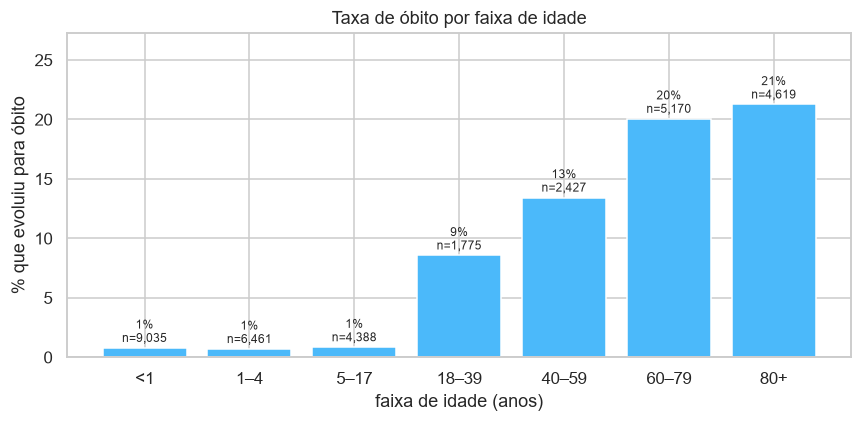

In [6]:
faixas = pd.cut(X_todos["idade_anos"], [0, 1, 5, 18, 40, 60, 80, 120], right=False,
                labels=["<1", "1–4", "5–17", "18–39", "40–59", "60–79", "80+"])
por_idade = y_todos.groupby(faixas, observed=True).agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(por_idade.index.astype(str), por_idade["mean"] * 100, color="#4BB9FA")
for i, (taxa, n) in enumerate(zip(por_idade["mean"], por_idade["size"])):
    ax.text(i, taxa * 100 + 0.5, f"{taxa:.0%}\nn={n:,}", ha="center", fontsize=8)
ax.set_ylabel("% que evoluiu para óbito")
ax.set_xlabel("faixa de idade (anos)")
ax.set_title("Taxa de óbito por faixa de idade")
ax.set_ylim(0, por_idade["mean"].max() * 100 + 6)
fig.tight_layout()
fig.savefig(FIGURAS / "02_obito_por_idade.png")
plt.show()

### Divisão em treino e teste (temporal)

Em vez de sortear as linhas, separamos **pelo tempo**: o modelo aprende com **2024** e é testado em **2025**.
É o uso real: a Zela é treinada com o passado e usada no futuro. Assim o teste também mede se o modelo aguenta a
mudança de vírus e de estação de um ano para o outro. O ano de 2025 **não** é usado em nenhuma decisão de
treino: validação cruzada, escolha de hiperparâmetros e do ponto de corte usam só 2024.

In [7]:
eh_treino = dados["ANO_BASE"].astype(int) == 2024
X_treino, y_treino = X_todos[eh_treino], y_todos[eh_treino]
X_teste, y_teste = X_todos[~eh_treino], y_todos[~eh_treino]
pd.DataFrame({
    "conjunto": ["treino (2024)", "teste (2025)"],
    "casos": [len(y_treino), len(y_teste)],
    "taxa de óbito": [y_treino.mean(), y_teste.mean()],
}).style.format({"taxa de óbito": "{:.1%}"}).hide(axis="index")

conjunto,casos,taxa de óbito
treino (2024),16662,7.2%
teste (2025),17213,8.4%


## 3. Escolha do modelo

**XGBoost** (árvores com *gradient boosting*) é a escolha principal porque:
1. os dados são uma **tabela** com variáveis sim/não, contagens e idade, terreno onde modelos de árvore costumam
   ser os mais fortes;
2. ele lida com **valores faltantes** nativamente (muitos campos vêm "ignorado"), sem imputação inventada;
3. captura **interações** (por exemplo, falta de ar pesa mais em idosos) sem precisar criá-las à mão;
4. permite medir a **importância de cada sinal**, que é o que a Zela quer saber.

Os óbitos são poucos (cerca de 8% dos casos), então só a acurácia enganaria: um modelo que diz "ninguém morre"
acerta 92%. Por isso olhamos métricas que não se iludem com a classe rara.

Para provar que a complexidade vale a pena, comparamos com duas referências na **validação cruzada de 5 partes
(só no treino)**: um classificador "burro" (sempre chuta a classe mais comum) e uma regressão logística.

**Métrica principal: ROC-AUC** (quão bem o modelo ordena quem está em maior e menor risco, independente do ponto
de corte). Também olhamos a **PR-AUC** (mais exigente com a classe rara), o **recall** (dos que morreram, quantos o
modelo teria sinalizado), porque na triagem deixar passar um caso grave é o pior erro, e a **precisão**.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
referencias = {
    "Sempre 'não evolui para óbito'": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=2000)),
    "XGBoost (padrão)": XGBClassifier(random_state=SEMENTE, n_jobs=-1, eval_metric="logloss"),
}
linhas = []
for nome, modelo in referencias.items():
    r = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=["roc_auc", "average_precision"],
                       return_train_score=True)
    linhas.append({"modelo": nome,
                   "ROC-AUC treino": r["train_roc_auc"].mean(), "ROC-AUC validação": r["test_roc_auc"].mean(),
                   "PR-AUC validação": r["test_average_precision"].mean()})
pd.DataFrame(linhas).style.format(precision=3).hide(axis="index")

modelo,ROC-AUC treino,ROC-AUC validação,PR-AUC validação
Sempre 'não evolui para óbito',0.500,0.500,0.072
Regressão logística,0.867,0.863,0.334
XGBoost (padrão),0.987,0.874,0.449


## 4. Treino com diferentes hiperparâmetros

Testamos **36 combinações** de três hiperparâmetros do XGBoost, sempre com validação cruzada de 5 partes **só no
treino (2024)**:

| hiperparâmetro | o que controla | valores |
|---|---|---|
| `max_depth` | profundidade de cada árvore (complexidade) | 2, 4, 6, 8 |
| `learning_rate` | tamanho do passo de cada nova árvore | 0,03 · 0,1 · 0,3 |
| `n_estimators` | quantidade de árvores | 100 · 300 · 600 |

In [9]:
grade = {"max_depth": [2, 4, 6, 8], "learning_rate": [0.03, 0.1, 0.3], "n_estimators": [100, 300, 600]}
busca = GridSearchCV(
    XGBClassifier(random_state=SEMENTE, n_jobs=-1, eval_metric="logloss", tree_method="hist"),
    grade, scoring="roc_auc", cv=cv, return_train_score=True, n_jobs=1, refit=True)
busca.fit(X_treino, y_treino)

resultados = (pd.DataFrame(busca.cv_results_)
              .rename(columns={"param_max_depth": "max_depth", "param_learning_rate": "learning_rate",
                               "param_n_estimators": "n_estimators",
                               "mean_train_score": "AUC treino", "mean_test_score": "AUC validação",
                               "std_test_score": "desvio validação"})
              [["max_depth", "learning_rate", "n_estimators", "AUC treino", "AUC validação",
                "desvio validação", "rank_test_score"]]
              .assign(**{"diferença (overfitting)": lambda d: d["AUC treino"] - d["AUC validação"]})
              .sort_values("rank_test_score"))
print("Melhor combinação:", busca.best_params_, f"| AUC validação = {busca.best_score_:.3f}")
resultados.style.format(precision=3).hide(axis="index")

Melhor combinação: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 300} | AUC validação = 0.897


max_depth,learning_rate,n_estimators,AUC treino,AUC validação,desvio validação,rank_test_score,diferença (overfitting)
4,0.030,300,0.929,0.897,0.004,1,0.032
4,0.100,100,0.931,0.897,0.005,2,0.035
4,0.030,100,0.913,0.895,0.003,3,0.018
2,0.100,300,0.914,0.895,0.006,4,0.019
2,0.030,600,0.909,0.895,0.004,5,0.014
4,0.030,600,0.942,0.895,0.005,6,0.047
2,0.300,100,0.914,0.895,0.007,7,0.020
2,0.100,600,0.922,0.894,0.007,8,0.027
2,0.100,100,0.903,0.893,0.004,9,0.010
6,0.030,100,0.935,0.893,0.003,10,0.042


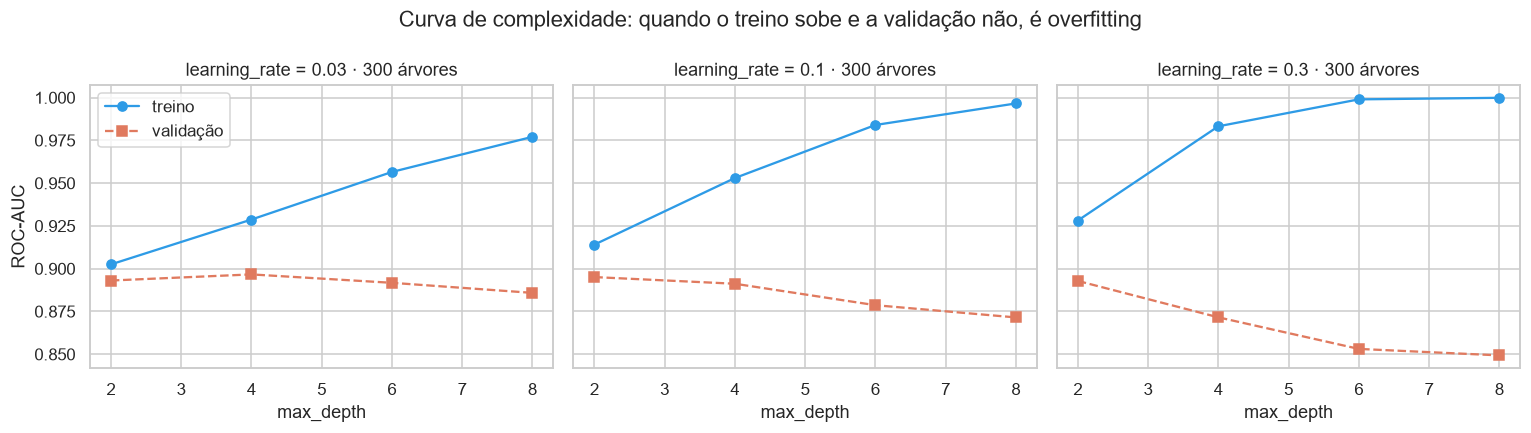

In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for eixo, taxa in zip(eixos, grade["learning_rate"]):
    parte = resultados[(resultados["learning_rate"] == taxa) & (resultados["n_estimators"] == 300)]
    parte = parte.sort_values("max_depth")
    eixo.plot(parte["max_depth"], parte["AUC treino"], "o-", label="treino", color="#2E9BE6")
    eixo.plot(parte["max_depth"], parte["AUC validação"], "s--", label="validação", color="#E07A5F")
    eixo.set_title(f"learning_rate = {taxa} · 300 árvores")
    eixo.set_xlabel("max_depth")
eixos[0].set_ylabel("ROC-AUC")
eixos[0].legend()
fig.suptitle("Curva de complexidade: quando o treino sobe e a validação não, é overfitting")
fig.tight_layout()
fig.savefig(FIGURAS / "03_overfitting_max_depth.png")
plt.show()

### Ponto de corte pensado para a triagem

O modelo devolve uma probabilidade. Para virar "alerta de risco" é preciso um ponto de corte. Como na triagem
**perder um caso grave é pior do que um alarme a mais**, escolhemos o maior corte que ainda sinaliza **pelo menos
80% dos casos que evoluíram para óbito**. A escolha usa as previsões *fora da dobra* da validação cruzada no treino (2024), nunca o teste.

In [11]:
melhor = busca.best_estimator_
prob_oof = cross_val_predict(melhor, X_treino, y_treino, cv=cv, method="predict_proba")[:, 1]
cortes = np.linspace(0.05, 0.95, 181)
recalls = np.array([recall_score(y_treino, prob_oof >= c) for c in cortes])
CORTE = float(cortes[recalls >= 0.80].max())
print(f"Ponto de corte escolhido: {CORTE:.3f} (recall na validação cruzada = "
      f"{recall_score(y_treino, prob_oof >= CORTE):.1%})")

Ponto de corte escolhido: 0.100 (recall na validação cruzada = 81.1%)


## 5. Resultados em treino e teste

In [12]:
def metricas(y, prob, corte):
    previsto = prob >= corte
    return {"ROC-AUC": roc_auc_score(y, prob), "PR-AUC": average_precision_score(y, prob),
            "recall (óbitos sinalizados)": recall_score(y, previsto),
            "precisão (alertas certos)": precision_score(y, previsto),
            "F1": f1_score(y, previsto),
            "taxa de óbito real": y.mean()}

prob_treino = melhor.predict_proba(X_treino)[:, 1]
prob_teste = melhor.predict_proba(X_teste)[:, 1]
tabela = pd.DataFrame({"treino (2024)": metricas(y_treino, prob_treino, CORTE),
                       "validação cruzada (2024)": metricas(y_treino, prob_oof, CORTE),
                       "teste (2025)": metricas(y_teste, prob_teste, CORTE)})
tabela.style.format("{:.3f}")

,treino (2024),validação cruzada (2024),teste (2025)
ROC-AUC,0.925,0.896,0.866
PR-AUC,0.599,0.489,0.411
recall (óbitos sinalizados),0.872,0.811,0.770
precisão (alertas certos),0.282,0.261,0.251
F1,0.426,0.395,0.379
taxa de óbito real,0.072,0.072,0.084


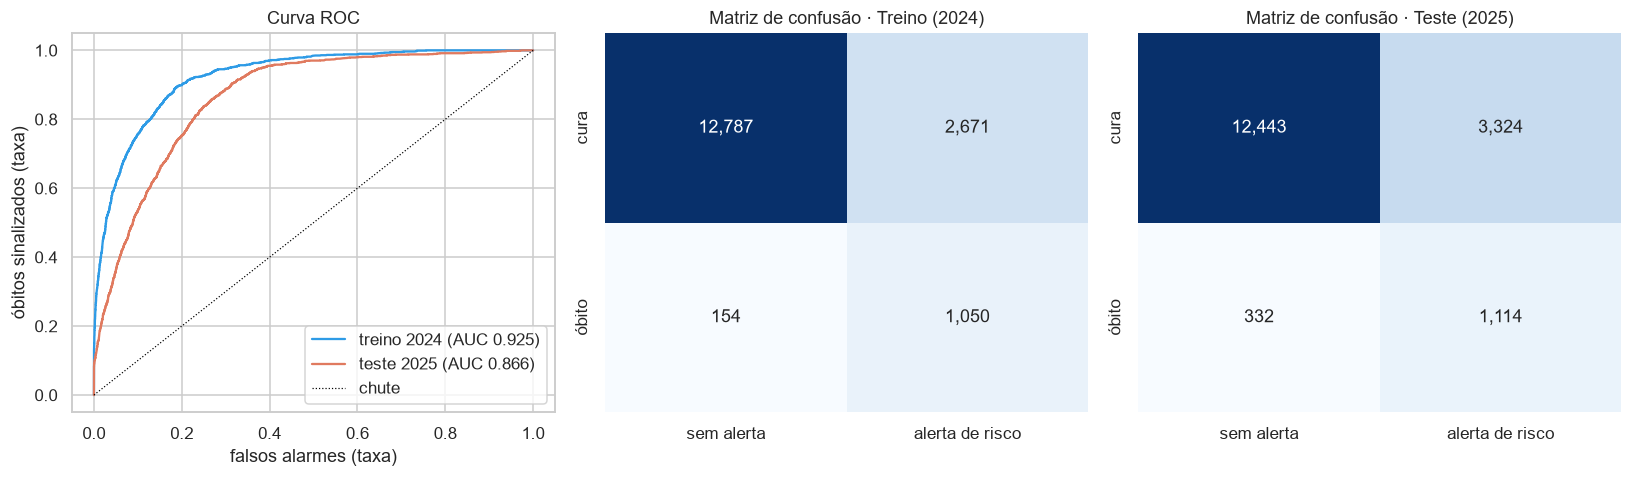

In [13]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for rotulo, y, prob, cor in [("treino 2024", y_treino, prob_treino, "#2E9BE6"),
                             ("teste 2025", y_teste, prob_teste, "#E07A5F")]:
    fpr, tpr, _ = roc_curve(y, prob)
    eixos[0].plot(fpr, tpr, color=cor, label=f"{rotulo} (AUC {roc_auc_score(y, prob):.3f})")
eixos[0].plot([0, 1], [0, 1], "k:", lw=0.8, label="chute")
eixos[0].set_xlabel("falsos alarmes (taxa)")
eixos[0].set_ylabel("óbitos sinalizados (taxa)")
eixos[0].set_title("Curva ROC")
eixos[0].legend(loc="lower right")

for eixo, (rotulo, y, prob) in zip(eixos[1:], [("Treino (2024)", y_treino, prob_treino),
                                               ("Teste (2025)", y_teste, prob_teste)]):
    matriz = confusion_matrix(y, prob >= CORTE)
    sns.heatmap(matriz, annot=True, fmt=",", cmap="Blues", cbar=False, ax=eixo,
                xticklabels=["sem alerta", "alerta de risco"], yticklabels=["cura", "óbito"])
    eixo.set_title(f"Matriz de confusão · {rotulo}")
fig.tight_layout()
fig.savefig(FIGURAS / "04_roc_e_matrizes.png")
plt.show()

### Quais sinais o modelo mais usa?

Usamos a **importância por permutação no teste (2025)**: embaralhamos uma variável de cada vez e medimos quanto o
ROC-AUC cai. Quanto maior a queda, mais o modelo depende daquele sinal para acertar.

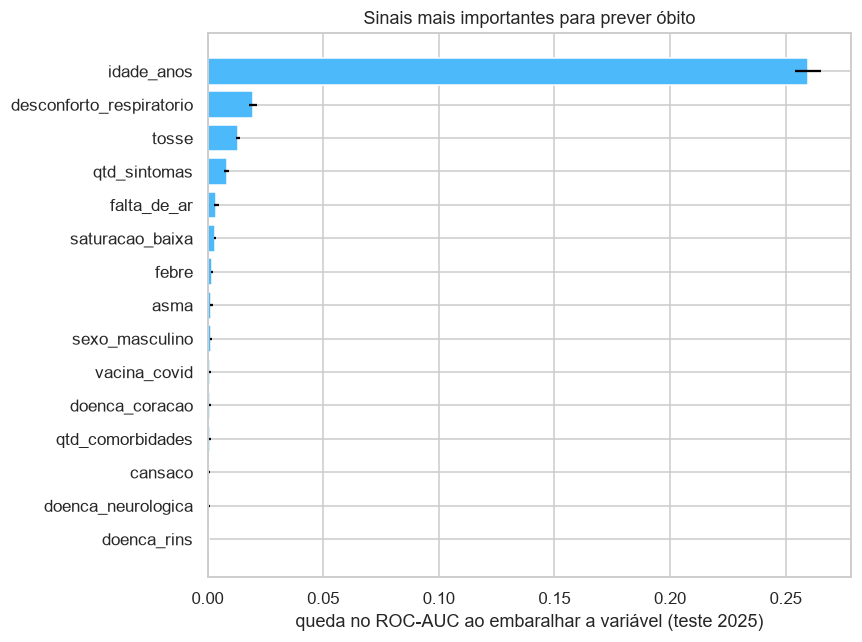

variavel,queda_auc,desvio
idade_anos,0.2597,0.0055
desconforto_respiratorio,0.0196,0.0017
tosse,0.0132,0.0007
qtd_sintomas,0.0083,0.0010
falta_de_ar,0.0038,0.0010
saturacao_baixa,0.0031,0.0004
febre,0.0021,0.0004
asma,0.0017,0.0005
sexo_masculino,0.0015,0.0005
vacina_covid,0.0012,0.0005


In [14]:
perm = permutation_importance(melhor, X_teste, y_teste, scoring="roc_auc", n_repeats=10,
                              random_state=SEMENTE, n_jobs=1)
importancia = (pd.DataFrame({"variavel": X_teste.columns, "queda_auc": perm.importances_mean,
                             "desvio": perm.importances_std})
               .sort_values("queda_auc", ascending=False))
top = importancia.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["variavel"], top["queda_auc"], xerr=top["desvio"], color="#4BB9FA")
ax.invert_yaxis()
ax.set_xlabel("queda no ROC-AUC ao embaralhar a variável (teste 2025)")
ax.set_title("Sinais mais importantes para prever óbito")
fig.tight_layout()
fig.savefig(FIGURAS / "05_importancia_variaveis.png")
plt.show()
importancia.head(15).style.format({"queda_auc": "{:.4f}", "desvio": "{:.4f}"}).hide(axis="index")

## 6. Leitura para a Zela

A triagem da Zela já trata como **vermelho** relatos como "falta de ar", "não consigo respirar" e "lábios roxos"
(`ia/app/dominio/triagem.py`). Abaixo cruzamos esses sinais com o desfecho real em 2025 (dados que o modelo
não viu no treino).

In [15]:
teste = X_teste.assign(obito=y_teste.values, prob=prob_teste)
grupos = {
    "todos os casos de SRAG": teste.index == teste.index,
    "falta de ar": teste["falta_de_ar"] == 1,
    "falta de ar + desconforto respiratório": (teste["falta_de_ar"] == 1) & (teste["desconforto_respiratorio"] == 1),
    "saturação < 95%": teste["saturacao_baixa"] == 1,
    "saturação < 95% + desconforto": (teste["saturacao_baixa"] == 1) & (teste["desconforto_respiratorio"] == 1),
    "60 anos ou mais": teste["idade_anos"] >= 60,
    "60 anos ou mais + saturação < 95%": (teste["idade_anos"] >= 60) & (teste["saturacao_baixa"] == 1),
    "80 anos ou mais + saturação < 95%": (teste["idade_anos"] >= 80) & (teste["saturacao_baixa"] == 1),
    "menos de 60 anos, sem falta de ar e sem saturação baixa":
        (teste["idade_anos"] < 60) & (teste["falta_de_ar"] == 0) & (teste["saturacao_baixa"] == 0),
    "alerta do modelo": teste["prob"] >= CORTE,
}
pd.DataFrame([{"grupo": nome, "pessoas": int(filtro.sum()), "evoluíram para óbito": teste.loc[filtro, "obito"].mean()}
              for nome, filtro in grupos.items()]).style.format({"evoluíram para óbito": "{:.1%}"}).hide(axis="index")

grupo,pessoas,evoluíram para óbito
todos os casos de SRAG,17213,8.4%
falta de ar,11054,10.6%
falta de ar + desconforto respiratório,8024,12.3%
saturação < 95%,12344,9.3%
saturação < 95% + desconforto,8844,10.6%
60 anos ou mais,5425,20.4%
60 anos ou mais + saturação < 95%,4001,21.6%
80 anos ou mais + saturação < 95%,1839,21.4%
"menos de 60 anos, sem falta de ar e sem saturação baixa",1103,1.2%
alerta do modelo,4438,25.1%


### Faixas de risco do modelo

Dividimos as pessoas de 2025 em cinco faixas iguais (quintis) pela probabilidade dada pelo modelo. Se o modelo
for útil, a taxa real de óbito tem que subir de uma faixa para a outra.

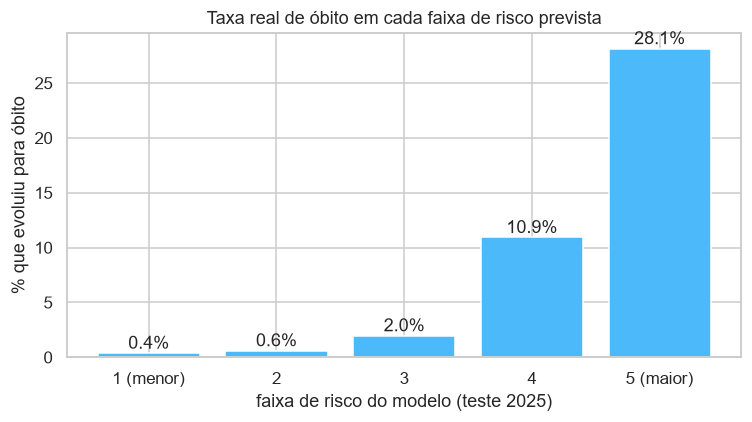

,pessoas,obitos,taxa_obito,idade_mediana
faixa_risco,,,,
1 (menor),3443,13,0.4%,1
2,3480,21,0.6%,1
3,3405,67,2.0%,1
4,3442,376,10.9%,71
5 (maior),3443,969,28.1%,74


In [16]:
teste["faixa_risco"] = pd.qcut(teste["prob"], 5, labels=["1 (menor)", "2", "3", "4", "5 (maior)"])
faixas_risco = teste.groupby("faixa_risco", observed=True).agg(
    pessoas=("obito", "size"), obitos=("obito", "sum"), taxa_obito=("obito", "mean"),
    idade_mediana=("idade_anos", "median"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(faixas_risco.index.astype(str), faixas_risco["taxa_obito"] * 100, color="#4BB9FA")
for i, taxa in enumerate(faixas_risco["taxa_obito"]):
    ax.text(i, taxa * 100 + 0.4, f"{taxa:.1%}", ha="center")
ax.set_xlabel("faixa de risco do modelo (teste 2025)")
ax.set_ylabel("% que evoluiu para óbito")
ax.set_title("Taxa real de óbito em cada faixa de risco prevista")
fig.tight_layout()
fig.savefig(FIGURAS / "06_faixas_de_risco.png")
plt.show()
faixas_risco.style.format({"taxa_obito": "{:.1%}", "idade_mediana": "{:.0f}"})

## 7. Conclusão

O texto completo, com os números finais e as limitações, está em `RELATORIO_ML.md`, na raiz do repositório.
Em resumo:

- **O modelo funciona e generaliza para o ano seguinte.** Treinado só com 2024, ele ordena o risco de óbito de 2025
  com ROC-AUC de 0,87 (0,90 na validação cruzada). A queda pequena de treino → validação → teste mostra que não
  houve decoreba. As combinações mais profundas e com passo maior chegaram a 0,99 no treino, mas pioraram na
  validação: é o overfitting que a busca de hiperparâmetros evitou.
- **O alerta é útil na prática.** Com o corte escolhido no treino, o modelo sinaliza cerca de 1 em cada 4 pessoas de
  2025 e encontra 77% dos óbitos. Entre os sinalizados, 1 em 4 morreu (3 vezes a média). Na faixa de maior risco,
  28% morreram; na de menor, 0,4%.
- **O que pesa:** a **idade** é de longe o fator mais forte (60+ anos: 20% de óbito; abaixo de 60 anos, sem falta de
  ar e sem saturação baixa: 1,2%). Depois vêm os sinais respiratórios (**desconforto respiratório, falta de ar,
  saturação baixa**) e as doenças crônicas (diabetes, pulmão, coração). Isso **confirma** os sinais vermelhos da
  Zela e indica um ajuste: **idade 60+ com falta de ar** deve subir de nível na triagem.
- **Limite importante:** a base só tem pessoas que já foram notificadas com SRAG, ou seja, que chegaram a um serviço
  de saúde. O modelo **não** decide se alguém precisa procurar ajuda; ele mostra **quais sinais são de alarme** entre
  os casos respiratórios graves. Por isso, na Zela, ele serve para **subir** a prioridade, nunca para rebaixar
  um caso.